# Sentinel: training the two-stage attack detector

**Security of SDN group project, ML detection part.**

This notebook trains the detector that `sentinel/detector.py` runs live. It turns
the labelled feature table into a model file that the detector loads.

| Stage | Model | Trained on | Job |
| --- | --- | --- | --- |
| 1a. Volume path | Isolation Forest | Normal traffic only | Flag ports whose behaviour is far from normal, including attacks never seen in training |
| 1b. Identity path | Rule on `host_moves_in` | Nothing to train | Flag a port when a host appears there away from its home port (spoofing) |
| 2. Attack type | Random Forest | Labelled attack windows | Name the attack: `flood`, `slow_exhaustion`, `spoofing`, or `unknown` when unsure |

The threshold detector from our Lab 2 implementation is evaluated alongside as the **baseline** the ML detector must beat.

**Input:** `features.csv`, built from the raw ONOS recordings by `sentinel/features.py`
(one row per edge port every 2 s, 12 features over a 10 s window).
**Output:** `sentinel_model.joblib` with keys `iforest, tau, k, rf, min_conf, features, sklearn, spoof_min_moves, spoof_hold, volume_hold`.

**Runs in** Google Colab (files in Google Drive) or locally from the repo's `notebooks/` folder.

## 1. Setup and paths

In [30]:
import os, sys, json, subprocess
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE         = Path('/content/drive/MyDrive/sdn-sentinel')   # holds sentinel/, features.csv, the model
    CODE_DIR     = BASE                                         # folder that contains sentinel/
    FEATURES_CSV = BASE / 'features.csv'
    MODEL_OUT    = BASE / 'sentinel_model.joblib'
    RAW_DIR      = Path('/content/data')                        # unzipped recordings (optional)
    LABELS       = RAW_DIR / 'labels.jsonl'
    BUSY_CSV     = BASE / 'features_busy.csv'                    # extra test: attacks during busy traffic
else:
    ROOT         = Path('..').resolve()                         # repo root (this notebook is in notebooks/)
    CODE_DIR     = ROOT
    FEATURES_CSV = ROOT / 'data' / 'features.csv'
    MODEL_OUT    = ROOT / 'models' / 'sentinel_model.joblib'
    RAW_DIR      = ROOT / 'data' / 'raw'
    LABELS       = ROOT / 'data' / 'labels.jsonl'
    BUSY_CSV     = ROOT / 'data' / 'features_busy.csv'

SAMPLE_DIR = CODE_DIR / 'data' / 'sample'                       # small recordings for the replay check
print('features table :', FEATURES_CSV, '(exists)' if FEATURES_CSV.exists() else '(MISSING)')
print('model output   :', MODEL_OUT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
features table : /content/drive/MyDrive/sdn-sentinel/features.csv (exists)
model output   : /content/drive/MyDrive/sdn-sentinel/sentinel_model.joblib


**scikit-learn version.** A `.joblib` model only loads reliably in the scikit-learn
version that saved it, and the detector refuses to start otherwise. The version
printed here must match `scikit-learn==...` in `requirements.txt`.

In [31]:
import numpy as np, pandas as pd, joblib, sklearn
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.metrics import classification_report, confusion_matrix

pd.set_option('display.width', 250); pd.set_option('display.max_columns', 30)
print('scikit-learn', sklearn.__version__, '| numpy', np.__version__, '| pandas', pd.__version__)

req = CODE_DIR / 'requirements.txt'
if req.exists():
    pin = [l.split('==')[1].split()[0] for l in req.read_text().splitlines() if l.startswith('scikit-learn==')]
    if pin and pin[0] != sklearn.__version__:
        print(f'WARNING: requirements.txt pins scikit-learn {pin[0]}; update it or install that version.')

scikit-learn 1.6.1 | numpy 2.4.6 | pandas 2.2.3


## 2. Feature table

**Optional: rebuild it from the raw recordings.** Only needed if `features.py`
changed. It reads about 5.4 GB and takes around 20 minutes on Colab.

In [32]:
REBUILD = False

if REBUILD:
    out = subprocess.run([sys.executable, str(CODE_DIR / 'sentinel' / 'features.py'), str(RAW_DIR),
                          '--labels', str(LABELS), '--out', str(FEATURES_CSV)],
                         capture_output=True, text=True)
    print(out.stderr[-4000:])

In [33]:
d = pd.read_csv(FEATURES_CSV)
d['port'] = d['port'].astype(str)
d['is_attack'] = d['label'] != 'normal'
print(d.shape, 'rows x columns |', d.run_id.nunique(), 'runs')
print('edge ports:', sorted(set(zip(d.switch, d.port))))
d.groupby(['label', 'split']).size().unstack(fill_value=0)

(43038, 20) rows x columns | 34 runs
edge ports: [('of:0000000000000001', '1'), ('of:0000000000000001', '2'), ('of:0000000000000002', '1'), ('of:0000000000000002', '2'), ('of:0000000000000003', '1'), ('of:0000000000000003', '2')]


split,test,train,val
label,,,
flood,141,222,72
normal,11135,23080,7960
slow_exhaustion,72,107,36
spoofing,71,107,35


**Columns.** `ts, run_id, switch, port`, the 12 features, then:
`label` (`normal`, `flood`, `slow_exhaustion`, `spoofing`), `split` (`train`, `val`, `test`),
and `phase` (`normal_run`, `pre`, `attack`, `post`: where in the run the window sits).

**Labelling rule.** A window gets the attack label only if it is on the attacker's port
**and** overlaps the attack interval in `labels.jsonl`. Everything else is `normal`.

**Split by run, never by shuffled rows.** Neighbouring windows are nearly identical, so a
row-level split would leak test data into training. Attack runs: per scenario, the last 2
runs are test, the one before is validation, the rest train. Normal runs are too few to
split by run, so each is split in time: first 60% train, next 20% validation, last 20% test.

### 2.1 Average features per label and phase

In [34]:
ALL_FEATURES = ['new_flows', 'new_flows_max_step', 'burstiness', 'active_steps',
                'uniq_src_mac', 'uniq_dst_mac', 'rx_pkts', 'flows_per_pkt',
                'hosts_on_port', 'host_moves_in', 'table_size_sw', 'table_growth']
d.groupby(['label', 'phase'])[ALL_FEATURES].mean().round(2)

new_flows  new_flows_max_step  burstiness  active_steps  uniq_src_mac  uniq_dst_mac  rx_pkts  flows_per_pkt  hosts_on_port  host_moves_in  table_size_sw  table_growth
label           phase                                                                                                                                                                             
flood           attack         353.50              126.58       41.65          3.02       1423.03          3.51   356.98           1.89       25676.81           0.00        1159.40         77.96
normal          attack           0.44                0.39        0.16          0.44          0.96          2.31    42.44           0.11           0.96           0.00         622.85         43.34
                normal_run       0.40                0.37        0.15          0.27          0.71          1.87  2021.71           0.08         804.65           0.00          10.61          0.00
                post             0.31                0.28        0.11          0.31          9.17          1.52     2.46           0.10        2986.14           0.00          26.33        -33.65
                pre              0.53                0.45        0.19          0.53          0.82          1.45     3.28           0.16        3200.07           0.00           8.40          0.61
slow_exhaustion attack          61.70               15.49        3.51          4.37        168.97          2.71    65.02           0.98       29431.72           0.00         134.33         16.69
spoofing        attack           0.42                0.37        0.15          0.39          0.77          1.42    18.42           0.04           1.87           0.35           8.73          0.01

### 2.2 Data-quality decisions

1. **`hosts_on_port` is dropped.** *Observed* (table below): an average of 1,341 hosts per port
   in each normal scenario S1 to S3, rising from about 2,900 to 5,700 across the flood scenarios
   S4 to S6 in recording order (tens of thousands on the attacker's port during a flood, see 2.1),
   and about 1 in the spoofing runs S7. *Confirmed cause:* ONOS learns each spoofed source MAC of a flood as a
   host and keeps it. The ONOS topology view after a flood shows hundreds of such phantom hosts on
   switch s1, each with a random MAC and no IP address (`docs/phantom_hosts.jpeg`). These entries
   carried over between recordings. The feature therefore tracks ONOS's leftover state rather than
   the attack in the current window: kept in, the model could learn "few hosts means spoofing" and
   misjudge normal traffic on a fresh ONOS.
2. **Two short runs from Nov 7** (22 s and 31 s) are listed in `labels.jsonl` but have no recording
   in the dataset, so they are not used. `features.py` also excludes them by name.
3. **S2_run2** had no line in `labels.jsonl`. It is a normal run, so it was labelled
   normal for its whole duration, using the recording's own first and last timestamps.
4. **`host_moves_in` counts only arrivals away from a host's home port** (the first port it was
   seen on). During spoofing the victim's MAC moves back and forth between the attacker's port and
   the victim's own port, so with the first definition both ports registered moves. *Observed:*
   identity-path precision on the test split went from 0.42 to 1.00 with this rule, and in the
   replay of S7_run6 only the attacker's port s1:1 was flagged.
5. **The first recordings contained no bulk traffic.** The traffic generator hides command output,
   so a missing `iperf` failed silently: in the 9 Nov runs, host ports received only tens of packets
   per 10 s (section 2.6). The two S2 runs from 9 Nov are therefore kept as **idle** normal traffic
   (`S0_idle_run1/2`), and four runs re-recorded on 17 Nov with working iperf were added
   (`S2_iperf_run1/2`, `S3_iperf_run1/2`, labelled normal for their whole duration). Normal traffic
   now ranges from silent to several thousand packets per second on a port.

In [35]:
d.groupby(d.run_id.str[:2])['hosts_on_port'].mean().round(0).rename('mean hosts_on_port per scenario')

,mean hosts_on_port per scenario
run_id,
S0,1341.0
S1,1341.0
S2,1.0
S3,671.0
S4,2905.0
S5,4903.0
S6,5731.0
S7,1.0


### 2.4 Sanity checks on the table

Catches the usual silent problems: missing or duplicated rows, impossible values, stale port
counters, leakage between splits, labels on the wrong port or outside the attack, and gaps in
the recorder's 2 s pace.

In [36]:
print('missing values      :', int(d[ALL_FEATURES].isna().sum().sum()))
print('duplicate rows      :', int(d.duplicated(['run_id', 'switch', 'port', 'ts']).sum()))
neg = {f: int((d[f] < 0).sum()) for f in ALL_FEATURES if f != 'table_growth' and (d[f] < 0).any()}
print('negative values     :', neg or 'none')
print('flows_per_pkt > 1   :', f"{(d.flows_per_pkt > 1).mean():.1%} of rows (more new flows than packets = port counters lag)")
z = d.rx_pkts == 0
print('rx_pkts == 0        :', f"{z.mean():.1%} of rows | by label:", d.assign(z=z).groupby('label').z.mean().round(3).to_dict())
print('new flows but 0 packets received:', int(((d.new_flows > 0) & z).sum()), 'rows, of which attack rows:',
      int(((d.new_flows > 0) & z & d.is_attack).sum()))

per_run = d.assign(edge_port=d.switch + ':' + d.port).groupby('run_id').agg(
    rows=('ts', 'size'), edge_ports=('edge_port', 'nunique'),
    splits=('split', 'nunique'), attack_rows=('is_attack', 'sum'))
leak = [r for r, n in per_run.splits.items() if n > 1 and not r.startswith(('S1', 'S2', 'S3'))]
print('attack runs in >1 split:', leak or 'none')

att = d[d.is_attack]
print('attack ports        :', sorted(set(att.switch.str[-1] + ':' + att.port)))
print('attack rows outside attack phase:', int((att.phase != 'attack').sum()))

steps = d.drop_duplicates(['run_id', 'ts']).sort_values(['run_id', 'ts']).groupby('run_id').ts.diff().dropna()
print('time between snapshots (s): median %.2f | 95th pct %.2f | max %.1f | gaps over 5 s: %d'
      % (steps.median(), steps.quantile(.95), steps.max(), (steps > 5).sum()))
per_run[['rows', 'edge_ports', 'attack_rows']].T

missing values      : 0
duplicate rows      : 0
negative values     : none
flows_per_pkt > 1   : 0.9% of rows (more new flows than packets = port counters lag)
rx_pkts == 0        : 33.8% of rows | by label: {'flood': 0.011, 'normal': 0.344, 'slow_exhaustion': 0.019, 'spoofing': 0.014}
new flows but 0 packets received: 1006 rows, of which attack rows: 8
attack runs in >1 split: ['S0_idle_run1', 'S0_idle_run2']
attack ports        : ['1:1']
attack rows outside attack phase: 0
time between snapshots (s): median 2.00 | 95th pct 2.00 | max 3.1 | gaps over 5 s: 0


run_id,S0_idle_run1,S0_idle_run2,S1_20261109_014048,S1_20261109_015712,S2_iperf_run1,S2_iperf_run2,S3_20261109_034446,S3_20261109_040207,S3_iperf_run1,S3_iperf_run2,S4_20261109_013500,S4_20261109_041901,S4_20261109_042348,S4_20261109_042910,S4_20261109_043427,...,S5_20261109_052108,S5_20261109_052444,S5_20261109_052816,S6_20261109_053339,S6_20261109_053701,S6_20261109_054029,S6_20261109_054355,S6_20261109_054806,S6_20261109_055147,S7_20261109_061137,S7_20261109_061501,S7_20261109_061827,S7_20261109_062142,S7_20261109_062532,S7_20261109_063128
rows,2730,2730,2724,2718,2730,2730,2730,2730,2730,2730,534,786,858,858,1350,...,588,540,570,546,552,546,552,570,540,546,564,540,648,1020,792
edge_ports,6,6,6,6,6,6,6,6,6,6,6,6,6,6,6,...,6,6,6,6,6,6,6,6,6,6,6,6,6,6,6
attack_rows,0,0,0,0,0,0,0,0,0,0,36,35,35,34,33,...,36,36,36,39,39,38,38,38,37,36,35,36,35,35,36


### 2.5 What separates the classes (log scale)

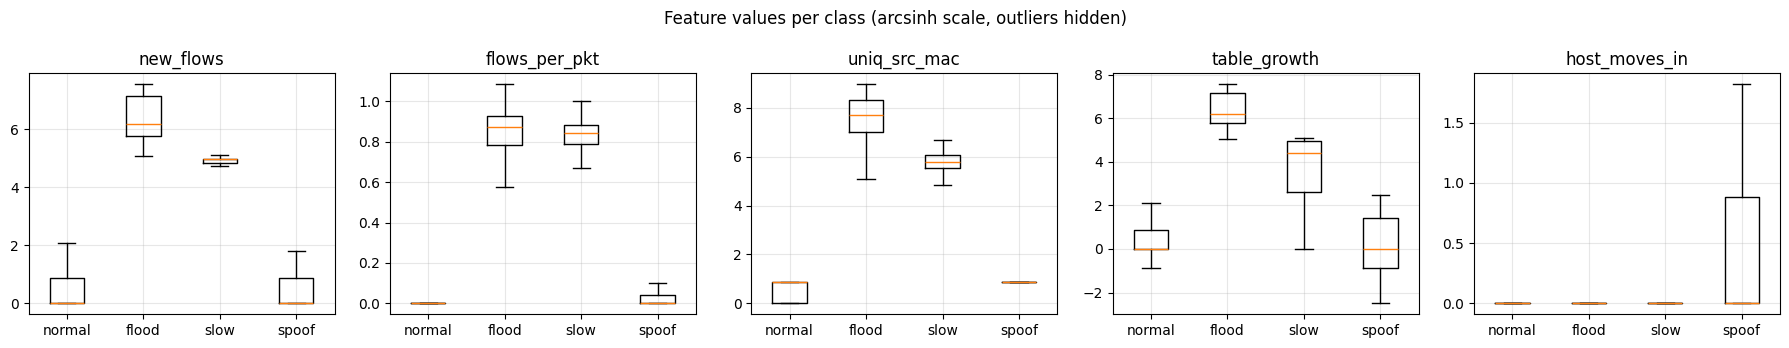

In [37]:
show = ['new_flows', 'flows_per_pkt', 'uniq_src_mac', 'table_growth', 'host_moves_in']
order = ['normal', 'flood', 'slow_exhaustion', 'spoofing']
fig, axes = plt.subplots(1, len(show), figsize=(18, 3.5))
for ax, f in zip(axes, show):
    data = [np.arcsinh(d.loc[d.label == c, f]) for c in order]
    ax.boxplot(data, showfliers=False)
    ax.set_xticks(range(1, len(order) + 1), ['normal', 'flood', 'slow', 'spoof'])
    ax.set_title(f); ax.grid(alpha=.3)
fig.suptitle('Feature values per class (arcsinh scale, outliers hidden)')
plt.tight_layout(); plt.show()

### 2.6 Data audit: traffic realism, attack runs and label timing

Checks that the recordings contain what the scenarios claim: how much legitimate traffic there
is, whether each attack really happened on the attacker's port, whether labels line up in time
with the attack, and which features carry overlapping information.

In [38]:
sc = d.run_id.str[:2]
print('1. Legitimate traffic volume: packets received per port per 10 s (normal windows only).')
print('   A working iperf transfer would show thousands; pings alone show tens.')
display(d[~d.is_attack].groupby([sc.rename('scenario'), 'phase'])['rx_pkts']
        .agg(['mean', 'max']).round(1).unstack('phase'))

print('\n2. Per attack run: did the attack happen, on which port, how strongly?')
rows = []
for rid, run in d[sc.isin(['S4', 'S5', 'S6', 'S7'])].groupby('run_id'):
    att = run[run.is_attack]
    sw, pt = att.switch.iloc[0], att.port.iloc[0]
    me = run[(run.switch == sw) & (run.port == pt)]
    others = run[(run.phase == 'attack') & ~((run.switch == sw) & (run.port == pt))]
    first_attack = att.ts.min()
    sig = me[(me.new_flows > 20) | (me.host_moves_in > 0)]
    rows.append({'run': rid, 'label': att.label.iloc[0], 'split': run.split.iloc[0],
                 'attack windows': len(att),
                 'new_flows before': me.loc[me.phase == 'pre', 'new_flows'].mean(),
                 'new_flows during': att.new_flows.mean(),
                 'new_flows after': me.loc[me.phase == 'post', 'new_flows'].mean(),
                 'peak flow table': run.table_size_sw.max(),
                 'host moves, attacker port': att.host_moves_in.sum(),
                 'host moves, other ports': others.host_moves_in.sum(),
                 'label lag (s)': (sig.ts.min() - first_attack) if len(sig) else None})
audit = pd.DataFrame(rows).set_index('run')
display(audit.round(1))
print('   label lag = seconds between the first window labelled attack and the first visible attack signal')
print('   on the attacker port (new_flows > 20 or a host move). Near 0 to 10 s means the labels line up.')

print('\n3. Checks that should all say OK:')
chk = {
    'every attack run has attack windows': (audit['attack windows'] > 0).all(),
    'floods raise new_flows during the attack': (audit.query("label != 'spoofing'")['new_flows during']
                                                  > 5 * audit.query("label != 'spoofing'")['new_flows before'].clip(lower=1)).all(),
    'spoofing shows host moves on the attacker port': (audit.query("label == 'spoofing'")['host moves, attacker port'] > 0).all(),
    'no host moves on other ports during attacks': (audit['host moves, other ports'] == 0).all(),
    'labels line up with the signal (lag 0 to 12 s)': audit['label lag (s)'].dropna().between(-2, 12).all(),
    'no host moves at all in normal runs': (d.loc[d.phase == 'normal_run', 'host_moves_in'] == 0).all(),
}
for k, v in chk.items():
    print(f'   {"OK  " if v else "FAIL"}  {k}')

print('\n4. Strongly overlapping features in normal training data (|Spearman| > 0.95): information only')
corr = d[(d.split == 'train') & (d.phase == 'normal_run')][[f for f in ALL_FEATURES if f != 'hosts_on_port']].corr('spearman').abs()
pairs = [(a, b, round(corr.loc[a, b], 3)) for i, a in enumerate(corr) for b in corr.columns[i + 1:] if corr.loc[a, b] > 0.95]
print('   ', pairs or 'none')

1. Legitimate traffic volume: packets received per port per 10 s (normal windows only).
   A working iperf transfer would show thousands; pings alone show tens.


mean                         max                       
phase    attack normal_run post  pre attack normal_run  post   pre
scenario                                                          
S0          NaN        0.2  NaN  NaN    NaN        8.0   NaN   NaN
S1          NaN        8.9  NaN  NaN    NaN       20.0   NaN   NaN
S2          NaN     7187.5  NaN  NaN    NaN    43207.0   NaN   NaN
S3          NaN     1452.7  NaN  NaN    NaN    46655.0   NaN   NaN
S4        117.8        NaN  1.5  3.2  985.0        NaN  21.0  18.0
S5         16.3        NaN  4.1  3.4  107.0        NaN  23.0  17.0
S6         35.2        NaN  3.9  3.2  332.0        NaN  15.0  15.0
S7          3.7        NaN  2.1  3.2   22.0        NaN  15.0  15.0


2. Per attack run: did the attack happen, on which port, how strongly?


,label,split,attack windows,new_flows before,new_flows during,new_flows after,peak flow table,"host moves, attacker port","host moves, other ports",label lag (s)
run,,,,,,,,,,
S4_20261109_013500,flood,train,36,0.4,544.9,0.2,3941,0,0,0.0
S4_20261109_041901,flood,train,35,0.8,560.4,0.3,3939,0,0,0.0
S4_20261109_042348,flood,train,35,1.1,560.4,0.4,3913,0,0,0.0
S4_20261109_042910,flood,val,34,0.4,576.8,0.2,3938,0,0,0.0
S4_20261109_043427,flood,test,33,0.6,594.4,0.2,3943,0,0,2.0
S4_20261109_044226,flood,test,33,0.5,594.4,0.1,3942,0,0,2.0
S5_20261109_050959,slow_exhaustion,train,36,0.4,61.6,0.3,379,0,0,4.0
S5_20261109_051410,slow_exhaustion,train,35,0.3,62.2,0.4,224,0,0,2.0
S5_20261109_051735,slow_exhaustion,train,36,0.7,61.4,0.2,357,0,0,4.0


   label lag = seconds between the first window labelled attack and the first visible attack signal
   on the attacker port (new_flows > 20 or a host move). Near 0 to 10 s means the labels line up.

3. Checks that should all say OK:
   OK    every attack run has attack windows
   OK    floods raise new_flows during the attack
   OK    spoofing shows host moves on the attacker port
   OK    no host moves on other ports during attacks
   OK    labels line up with the signal (lag 0 to 12 s)
   OK    no host moves at all in normal runs

4. Strongly overlapping features in normal training data (|Spearman| > 0.95): information only
    [('new_flows', 'new_flows_max_step', np.float64(0.997)), ('new_flows', 'burstiness', np.float64(1.0)), ('new_flows', 'active_steps', np.float64(0.993)), ('new_flows_max_step', 'burstiness', np.float64(0.997)), ('new_flows_max_step', 'active_steps', np.float64(0.988)), ('burstiness', 'active_steps', np.float64(0.992))]


## 3. Settings

All tunable values in one place. `SEED` makes every run give the same numbers.

In [39]:
DROP = ['hosts_on_port']                 # see 2.2
FEATURES = [f for f in ALL_FEATURES if f not in DROP]

K                  = 2     # volume path alerts after K consecutive abnormal windows (2 x 2 s)
TARGET_FA_PER_HOUR = 1.0   # tau = lowest threshold giving at most this many false alerts/hour on validation
SPOOF_MIN_MOVES    = 1     # identity path: at least this many away-from-home arrivals in the window ...
SPOOF_HOLD         = 5     # ... keeps the port flagged for 5 more windows (10 s)
VOLUME_HOLD        = 5     # a volume alert stays on for 5 more windows (10 s); 0 switches the hold off (see 9.3)
MIN_CONF           = 0.7   # below this Random Forest confidence the type is "unknown"
BASELINE_MAX_STEP  = 60    # Lab 2 rule: 30 new flows/s = 60 new flows in one 2 s step
SEED               = 42
GROUP = ['run_id', 'switch', 'port']

print('model features:', FEATURES)

model features: ['new_flows', 'new_flows_max_step', 'burstiness', 'active_steps', 'uniq_src_mac', 'uniq_dst_mac', 'rx_pkts', 'flows_per_pkt', 'host_moves_in', 'table_size_sw', 'table_growth']


**Helper functions.** Alerts are counted the way the live detector raises them:
per port, in time order, inside each run.

In [40]:
d = d.sort_values(GROUP + ['ts']).reset_index(drop=True)

def k_consecutive(flags, k):
    # True once a flag has been True for k windows in a row
    run = flags.groupby((~flags).cumsum()).cumsum()
    return run >= k

def hold(flags, n):
    # stay True for n windows after any True
    return flags.astype(int).rolling(n + 1, min_periods=1).max().astype(bool)

def per_port(df, series, fn):
    return series.groupby([df[g] for g in GROUP]).transform(fn)

def false_alerts_per_hour(df, col):
    # alert onsets on normal-run traffic, per hour of recording
    nr = df[df.phase == 'normal_run']
    onsets = nr.groupby(GROUP)[col].apply(lambda s: int((s & ~s.shift(fill_value=False)).sum())).sum()
    hours = nr.groupby('run_id')['ts'].agg(lambda t: t.max() - t.min()).sum() / 3600
    return (onsets / hours if hours else 0.0), hours

X = lambda df, feats=FEATURES: df[feats].to_numpy(dtype=float)

## 4. Stage 1a: Isolation Forest (volume path)

Trained on **normal-run windows only**, so it learns what normal looks like and needs no
attack examples. `arcsinh` puts the heavily skewed counts on a log-like scale (it also
handles the negative values of `table_growth`). It sits inside the pipeline, so the
detector applies the same transform automatically.

In [41]:
train_norm = d[(d.split == 'train') & (d.phase == 'normal_run')]
val_norm   = d[(d.split == 'val')   & (d.phase == 'normal_run')]

iforest = make_pipeline(FunctionTransformer(np.arcsinh),
                        IsolationForest(n_estimators=300, random_state=SEED))
iforest.fit(X(train_norm))
d['score'] = -iforest.score_samples(X(d))          # higher = more abnormal
print(f'trained on {len(train_norm)} normal windows')

trained on 16370 normal windows


### 4.1 Choosing the alert threshold `tau`

Instead of a fixed percentile, `tau` is the **lowest** threshold that keeps false alerts on
validation normal traffic at or below `TARGET_FA_PER_HOUR`, counted after the K-in-a-row
rule. Lower means more sensitive, so this is the most sensitive setting that stays quiet on
normal traffic. This step takes a minute or two.

In [42]:
val = d[d.split == 'val']
val_scores = d.loc[(d.split == 'val') & (d.phase == 'normal_run'), 'score'].to_numpy()
tau = None
for pct in np.linspace(95, 100, 501):
    t = float(np.percentile(val_scores, pct))
    f = per_port(val, val['score'] > t, lambda s: k_consecutive(s, K))
    fa, val_hours = false_alerts_per_hour(val.assign(f=f), 'f')
    if fa <= TARGET_FA_PER_HOUR:
        tau = t
        break
print(f'tau = {tau:.4f}  (percentile {pct:.1f} of validation-normal scores; '
      f'{fa:.2f} false alerts/hour on {val_hours:.2f} h of validation normal traffic)')

d['flag_volume_raw'] = per_port(d, d['score'] > tau, lambda s: k_consecutive(s, K))

tau = 0.7040  (percentile 100.0 of validation-normal scores; 0.00 false alerts/hour on 0.50 h of validation normal traffic)


### 4.2 Holding the alert

Once the volume path raises an alert, it stays on for `VOLUME_HOLD` more windows (10 s), the same
way the identity path does. This is smoothing of the model's output: it keeps an alert from
switching off and on during intermittent attacks such as pulsed floods, but it can never raise an
alert the model did not raise. Section 9.3 shows the effect of different hold lengths.

In [43]:
d['flag_volume'] = per_port(d, d['flag_volume_raw'], lambda s: hold(s, VOLUME_HOLD))

## 5. Stage 1b: identity path (spoofing)

Spoofing creates almost no new flows, so the Isolation Forest barely notices it. Its
signature is a host appearing on a port away from its home port, which never happens in
our normal traffic. One such arrival flags the port for the next 10 s.

In [44]:
d['flag_identity'] = per_port(d, d['host_moves_in'] >= SPOOF_MIN_MOVES, lambda s: hold(s, SPOOF_HOLD))
d['flag'] = d['flag_volume'] | d['flag_identity']

## 6. Baseline: the threshold detector from our Lab 2 implementation

The Lab 2 handout asks for a detector based on indicators such as an unusual frequency of
packet_in messages, without fixing a threshold. Our Lab 2 implementation (also in
`monitoring/rules.yml`) counts new flow rules, which under reactive forwarding follow the packet_in
rate: it fires when network-wide new flows per second stay above 30 for 3 s.
Here it is **approximated per port**: at least 60 new flows (30/s over one 2 s step) in some step of
the window, for K windows in a row. Because the 10 s windows overlap, a single burst step can satisfy
two consecutive windows, so this version fires **more easily** than the original sustained rule.
That favours the baseline, so it does not inflate the ML detector's advantage.

In [45]:
d['flag_base'] = per_port(d, d['new_flows_max_step'] >= BASELINE_MAX_STEP, lambda s: k_consecutive(s, K))

## 7. Stage 2: Random Forest (attack type)

Trained on attack windows only. `class_weight='balanced'` compensates for the different
number of windows per attack. When the top class probability is below `MIN_CONF`, the
detector reports `unknown` and the engine applies only a safe default.

In [46]:
train_att = d[(d.split == 'train') & d.is_attack]
rf = RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=SEED)
rf.fit(X(train_att), train_att['label'])

def predict_type(df):
    proba = rf.predict_proba(X(df))
    types = rf.classes_[proba.argmax(axis=1)].astype(object)
    types[proba.max(axis=1) < MIN_CONF] = 'unknown'
    return types, proba.max(axis=1)

print('classes:', list(rf.classes_), '| trained on', len(train_att), 'attack windows')

classes: ['flood', 'slow_exhaustion', 'spoofing'] | trained on 436 attack windows


## 8. Evaluation on the test split

Everything below uses only test runs, which the models never saw.

### 8.1 Detection: ML against the threshold rule

* **precision**: of the windows flagged, the share that really were attack windows
* **recall**: of the attack windows, the share flagged (per type in the second table)
* **false alerts/hour**: alert onsets on the normal runs (S1 to S3) per hour of recording. The test split has only about 30 minutes of normal traffic, so treat this as a rough estimate. Alerts on non-attacker ports *during attack runs* are not counted here; they lower the precision instead.
* **flagged in recovery**: share of after-attack windows still flagged

In [47]:
test = d[d.split == 'test'].copy()

def detection_row(df, col):
    tp = int((df[col] & df.is_attack).sum()); fp = int((df[col] & ~df.is_attack).sum())
    fn = int((~df[col] & df.is_attack).sum())
    fa, _ = false_alerts_per_hour(df, col)
    return {'precision': tp / (tp + fp) if tp + fp else 0.0,
            'recall': tp / (tp + fn) if tp + fn else 0.0,
            'false alerts/hour': fa,
            'flagged in recovery': df.loc[df.phase == 'post', col].mean()}

methods = {'ML, both paths': 'flag', 'ML volume path only': 'flag_volume',
           'ML identity path only': 'flag_identity', 'Threshold rule (our Lab 2 version)': 'flag_base'}
summary = pd.DataFrame({name: detection_row(test, col) for name, col in methods.items()}).T.round(3)
recall_by_type = pd.DataFrame({name: test[test.is_attack].groupby('label')[col].mean()
                               for name, col in methods.items()}).T.round(3)
print(f'test normal traffic: {false_alerts_per_hour(test, "flag")[1]:.2f} h')
display(summary)
display(recall_by_type.rename(columns=lambda c: f'recall {c}'))

test normal traffic: 0.50 h


,precision,recall,false alerts/hour,flagged in recovery
"ML, both paths",0.922,0.754,1.999,0.004
ML volume path only,0.914,0.676,1.999,0.004
ML identity path only,1.000,0.077,0.000,0.000
Threshold rule (our Lab 2 version),1.000,0.447,0.000,0.000


label,recall flood,recall slow_exhaustion,recall spoofing
"ML, both paths",0.879,0.944,0.31
ML volume path only,0.879,0.944,0.00
ML identity path only,0.000,0.000,0.31
Threshold rule (our Lab 2 version),0.901,0.000,0.00


### 8.2 Time to detect, per test attack run

Seconds from the first attack window to the first alert on the attacker's port
(empty = attack missed). The 10 s window plus the K-in-a-row rule set the floor.

In [48]:
def time_to_detect(df, col):
    out = {}
    for rid, g in df[df.phase != 'normal_run'].groupby('run_id'):
        att = g[g.is_attack]
        if att.empty:
            continue
        hit = att[att[col]]
        out[(att.label.iloc[0], rid)] = round(hit.ts.min() - att.ts.min(), 1) if len(hit) else None
    return pd.Series(out, dtype=object)

ttd = pd.DataFrame({'ML': time_to_detect(test, 'flag'), 'Threshold rule': time_to_detect(test, 'flag_base')})
ttd.index.names = ['attack', 'run']
caught = ttd.notna().sum()
print(f'attack runs detected: ML {caught["ML"]} of {len(ttd)}, threshold rule {caught["Threshold rule"]} of {len(ttd)}')
ttd

attack runs detected: ML 8 of 8, threshold rule 4 of 8


ML Threshold rule
attack          run                                   
flood           S4_20261109_043427  4.0            4.0
                S4_20261109_044226  6.0            4.0
slow_exhaustion S5_20261109_052444  4.0           None
                S5_20261109_052816  4.0           None
flood           S6_20261109_054806  6.0            4.0
                S6_20261109_055147  2.0            2.0
spoofing        S7_20261109_062532  0.0           None
                S7_20261109_063128  0.0           None

### 8.3 Anomaly score over time, one test run per attack

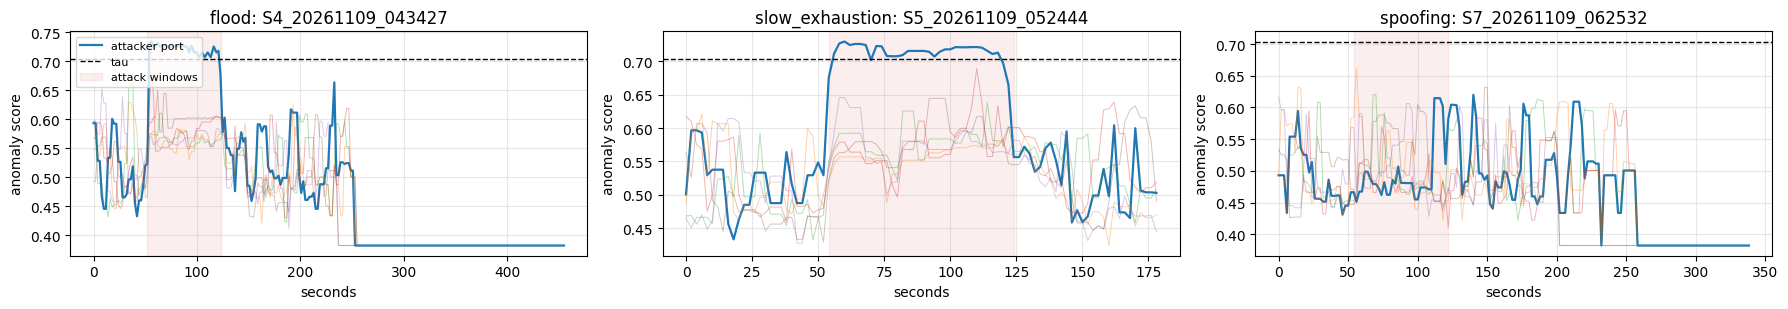

In [49]:
attack_runs = test[test.is_attack].groupby('label').run_id.first()
fig, axes = plt.subplots(1, len(attack_runs), figsize=(6 * len(attack_runs), 3.2), squeeze=False)
for ax, (label, rid) in zip(axes[0], attack_runs.items()):
    run = test[test.run_id == rid]
    lab = run[run.is_attack]
    sw, pt = lab.switch.iloc[0], lab.port.iloc[0]
    t0 = run.ts.min()
    for (s, p), g in run.groupby(['switch', 'port']):
        ax.plot(g.ts - t0, g.score, lw=1.6 if (s, p) == (sw, pt) else .7,
                alpha=1 if (s, p) == (sw, pt) else .35, label='attacker port' if (s, p) == (sw, pt) else None)
    ax.axhline(tau, color='k', ls='--', lw=1, label='tau')
    ax.axvspan(lab.ts.min() - t0, lab.ts.max() - t0, color='tab:red', alpha=.08, label='attack windows')
    ax.set_title(f'{label}: {rid}'); ax.set_xlabel('seconds'); ax.set_ylabel('anomaly score'); ax.grid(alpha=.3)
axes[0][0].legend(loc='upper left', fontsize=8)
plt.tight_layout(); plt.show()

### 8.4 Attack type (Random Forest)

Measured on all test attack windows, to judge the classifier on its own.

In [50]:
att_test = test[test.is_attack]
types, conf = predict_type(att_test)
print(classification_report(att_test['label'], types, zero_division=0))
order = sorted(set(att_test['label']) | set(types))
pd.DataFrame(confusion_matrix(att_test['label'], types, labels=order),
             index=[f'true {c}' for c in order], columns=[f'pred {c}' for c in order])

                 precision    recall  f1-score   support

          flood       1.00      0.92      0.96       141
slow_exhaustion       1.00      0.96      0.98        72
       spoofing       0.96      0.96      0.96        71
        unknown       0.00      0.00      0.00         0

       accuracy                           0.94       284
      macro avg       0.74      0.71      0.72       284
   weighted avg       0.99      0.94      0.96       284



,pred flood,pred slow_exhaustion,pred spoofing,pred unknown
true flood,130,0,3,8
true slow_exhaustion,0,69,0,3
true spoofing,0,0,68,3
true unknown,0,0,0,0


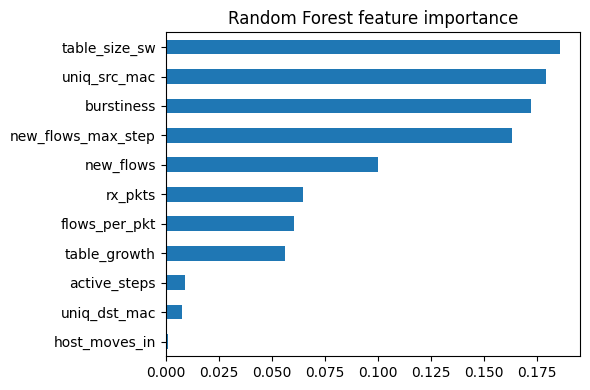

In [51]:
pd.Series(rf.feature_importances_, index=FEATURES).sort_values().plot.barh(figsize=(6, 4), title='Random Forest feature importance')
plt.tight_layout(); plt.show()

### 8.5 Extra test: attacks during busy traffic

Four attack runs recorded on 17 Nov with iperf running in the background (2 slow floods, 2 pulsed
floods). They are not used for training; the model above is applied to them unchanged. Skipped if
`features_busy.csv` is not available.

In [52]:
if BUSY_CSV.exists():
    b = pd.read_csv(BUSY_CSV); b['port'] = b['port'].astype(str); b['is_attack'] = b['label'] != 'normal'
    b = b.sort_values(GROUP + ['ts']).reset_index(drop=True)
    b['score'] = -iforest.score_samples(X(b))
    b['flag_volume'] = per_port(b, b['score'] > tau, lambda s: hold(k_consecutive(s, K), VOLUME_HOLD))
    b['flag_identity'] = per_port(b, b['host_moves_in'] >= SPOOF_MIN_MOVES, lambda s: hold(s, SPOOF_HOLD))
    b['flag'] = b['flag_volume'] | b['flag_identity']
    rows = []
    for rid, run in b.groupby('run_id'):
        att = run[run.is_attack]
        first = att.loc[att.flag, 'ts'].min()
        types, _ = predict_type(att)
        rows.append({'run': rid, 'attack': att.label.iloc[0], 'attack windows': len(att),
                     'caught': att.flag.mean(),
                     'seconds to first alert': None if pd.isna(first) else first - att.ts.min(),
                     'false-alarm windows': int(run.loc[~run.is_attack, 'flag'].sum()),
                     'type named correctly': (types == att.label.iloc[0]).mean()})
    display(pd.DataFrame(rows).set_index('run').round(2))
    print(f"overall: {b.loc[b.is_attack, 'flag'].mean():.3f} of attack windows caught, "
          f"{int(b.loc[~b.is_attack, 'flag'].sum())} false-alarm windows out of {int((~b.is_attack).sum())}")
else:
    print('features_busy.csv not found, skipped:', BUSY_CSV)

,attack,attack windows,caught,seconds to first alert,false-alarm windows,type named correctly
run,,,,,,
S5_20261117_134121,slow_exhaustion,36,0.94,4.00,5,0.92
S5_20261117_135015,slow_exhaustion,36,0.94,4.00,3,0.94
S6_20261117_135355,flood,39,0.79,12.01,0,0.87
S6_20261117_135725,flood,39,0.85,6.00,2,0.97


overall: 0.880 of attack windows caught, 10 false-alarm windows out of 2646


#### Where are the windows flagged outside an attack?

Here, we count every flagged window that isn’t labelled as attack as a “false-alarm window”. This check shows where they are. If they’re all on the attacker’s port (s1:1) in the post phase, they’re the 10 s alert hold (section 4.2) continuing just after the attack ended, not alarms on innocent ports.

In [60]:
display(b[~b.is_attack & b.flag].groupby(['run_id', 'switch', 'port', 'phase']).size().rename('flagged windows'))

,,,,flagged windows
run_id,switch,port,phase,
S5_20261117_134121,of:0000000000000001,1,post,5
S5_20261117_135015,of:0000000000000001,1,post,3
S6_20261117_135725,of:0000000000000001,1,post,2


Result: all 10 windows are on s1:1 in the post phase (5, 3 and 2 per run, never more than the 5-window hold). No innocent port was flagged during attacks under heavy iperf traffic.

## 9. Check: per-switch features

`table_size_sw` and `table_growth` are measured per **switch**, so during a flood on s1:1
the innocent port s1:2 shows the same large table. This retrains the volume path without
them, to see whether they help detection or only risk blaming the wrong port.

In [53]:
def volume_only(feats):
    m = make_pipeline(FunctionTransformer(np.arcsinh), IsolationForest(n_estimators=300, random_state=SEED))
    m.fit(X(train_norm, feats))
    s = -m.score_samples(X(d, feats))
    vs = s[((d.split == 'val') & (d.phase == 'normal_run')).to_numpy()]
    vmask = (d.split == 'val').to_numpy()
    for pct in np.linspace(95, 100, 501):
        t = float(np.percentile(vs, pct))
        f = per_port(d[vmask], pd.Series(s[vmask] > t, index=d.index[vmask]), lambda x: k_consecutive(x, K))
        if false_alerts_per_hour(d[vmask].assign(f=f), 'f')[0] <= TARGET_FA_PER_HOUR:
            break
    flag = per_port(d, pd.Series(s > t, index=d.index), lambda x: hold(k_consecutive(x, K), VOLUME_HOLD))
    tt = d.assign(f=flag)[d.split == 'test']
    row = detection_row(tt, 'f')
    row.update({f'recall {c}': v for c, v in tt[tt.is_attack].groupby('label')['f'].mean().items()})
    # innocent ports on the attacker's switch during attacks
    att_sw = tt[tt.is_attack][['run_id', 'switch']].drop_duplicates()
    inn = tt.merge(att_sw, on=['run_id', 'switch'])
    inn = inn[(inn.phase == 'attack') & ~inn.is_attack]
    row['innocent same-switch ports flagged'] = inn['f'].mean()
    return row

no_table = [f for f in FEATURES if f not in ('table_size_sw', 'table_growth')]
pd.DataFrame({'with table features': volume_only(FEATURES),
              'without table features': volume_only(no_table)}).T.round(3)

,precision,recall,false alerts/hour,flagged in recovery,recall flood,recall slow_exhaustion,recall spoofing,innocent same-switch ports flagged
with table features,0.914,0.676,1.999,0.004,0.879,0.944,0.0,0.0
without table features,1.000,0.042,0.000,0.000,0.085,0.000,0.0,0.0


### 9.1 Check: does normalising the features change anything?

Both models are tree-based: they only ask "is this feature above some value?", so rescaling a
feature moves the split points with it and gives the same result. This cell proves it on our data.

In [54]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler
test_rows = d[d.split == 'test']
for name, scaler in [('standard scaling', StandardScaler()), ('min-max scaling', MinMaxScaler())]:
    m = make_pipeline(FunctionTransformer(np.arcsinh), scaler,
                      IsolationForest(n_estimators=300, random_state=SEED)).fit(X(train_norm))
    diff = np.abs(m.score_samples(X(test_rows)) - iforest.score_samples(X(test_rows))).max()
    print(f'Isolation Forest + {name}: largest score difference = {diff}')
rf_scaled = make_pipeline(StandardScaler(), RandomForestClassifier(
    n_estimators=300, class_weight='balanced', random_state=SEED)).fit(X(train_att), train_att['label'])
att_rows = test_rows[test_rows.is_attack]
same = (rf_scaled.predict(X(att_rows)) == rf.predict(X(att_rows))).mean()
print(f'Random Forest + standard scaling: same prediction for {same:.1%} of test attack windows')

Isolation Forest + standard scaling: largest score difference = 0.0
Isolation Forest + min-max scaling: largest score difference = 0.0
Random Forest + standard scaling: same prediction for 100.0% of test attack windows


### 9.2 Check: why the volume path misses some flood windows

Splits the flood results into constant (S4) and pulsed (S6) floods, shows where in the attack the
misses happen and what missed windows look like, and calculates what a simple **burst rule**
(the per-port threshold approximation from section 6) would add if it ran alongside the model.
The burst rule is an analysis only; it is not part of the detector. It is also *not* the threshold
rule on the dashboard (`rules.yml`), which needs 3 consecutive seconds above 30 and misses pulsed
floods entirely. All ML numbers here include the 10 s hold (4.2).

In [55]:
fl = test[test.label == 'flood'].copy()
fl['scenario'] = fl.run_id.str[:2].map({'S4': 'S4 constant', 'S6': 'S6 pulsed'})
fl['t_in_attack'] = fl.ts - fl.groupby('run_id').ts.transform('min')
fl['above_tau'] = fl.score > tau
fl['outcome'] = np.select([fl.flag, fl.flag_base], ['caught by ML', 'missed by ML, caught by burst rule'], 'missed by both')

print('1. ML vs burst rule on flood windows (counts):')
display(pd.crosstab(fl.flag, fl.flag_base, rownames=['ML'], colnames=['burst rule']))
print('2. By flood type (share of windows):')
display(fl.groupby('scenario')[['flag', 'above_tau', 'flag_base']].mean().round(3)
        .rename(columns={'flag': 'ML', 'above_tau': 'score above tau', 'flag_base': 'burst rule'}))
print('3. Share caught by ML, by time into the attack:')
fl['attack_time'] = pd.cut(fl.t_in_attack, [-1, 10, 20, 30, 40, 50, 60, 90],
                           labels=['0-10s', '10-20s', '20-30s', '30-40s', '40-50s', '50-60s', '60s+'])
display(fl.pivot_table(index='scenario', columns='attack_time', values='flag', aggfunc='mean', observed=False).round(2))
print('4. Average features of caught and missed windows:')
display(fl.groupby('outcome')[FEATURES + ['score']].mean().round(2).T)
print('5. Calculated: ML and burst rule together (alert if either fires). Not built into detector.py.')
test['flag_combined'] = test.flag | test.flag_base
display(pd.DataFrame({'ML + burst rule': detection_row(test, 'flag_combined'),
                      'ML, both paths': detection_row(test, 'flag')}).T.round(3))
display(test[test.is_attack].groupby('label')[['flag', 'flag_combined']].mean().round(3)
        .rename(columns={'flag': 'ML', 'flag_combined': 'ML + burst rule'}))

1. ML vs burst rule on flood windows (counts):


burst rule,False,True
ML,,
False,10,7
True,4,120


2. By flood type (share of windows):


,ML,score above tau,burst rule
scenario,,,
S4 constant,0.924,0.909,0.924
S6 pulsed,0.840,0.667,0.880


3. Share caught by ML, by time into the attack:


attack_time,0-10s,10-20s,20-30s,30-40s,40-50s,50-60s,60s+
scenario,,,,,,,
S4 constant,0.5,1.0,1.0,1.0,1.0,1.0,1.00
S6 pulsed,0.6,1.0,0.9,1.0,0.6,1.0,0.81


4. Average features of caught and missed windows:


outcome,caught by ML,"missed by ML, caught by burst rule",missed by both
new_flows,398.06,195.00,54.00
new_flows_max_step,135.76,157.14,53.90
burstiness,42.42,64.63,21.55
active_steps,3.27,1.71,0.60
uniq_src_mac,1497.87,652.43,302.70
uniq_dst_mac,3.19,2.86,2.50
rx_pkts,407.73,161.29,9.70
flows_per_pkt,1.00,1.21,1.34
host_moves_in,0.00,0.00,0.00
table_size_sw,1224.58,665.00,88.70


5. Calculated: ML and burst rule together (alert if either fires). Not built into detector.py.


,precision,recall,false alerts/hour,flagged in recovery
ML + burst rule,0.925,0.778,1.999,0.004
"ML, both paths",0.922,0.754,1.999,0.004


,ML,ML + burst rule
label,,
flood,0.879,0.929
slow_exhaustion,0.944,0.944
spoofing,0.310,0.310


### 9.3 Choosing the alert hold

The same evaluation with the volume alert held for 0, 3, 5 or 10 extra windows. Holding makes alerts
last longer, not happen more often, so false alerts per hour stay the same; precision drops a little
because windows just after an attack ends stay flagged. The model uses `VOLUME_HOLD` from section 3.

In [56]:
rows = {}
for n in [0, 3, 5, 10]:
    vol = per_port(d, d['flag_volume_raw'], lambda s: hold(s, n)) if n else d['flag_volume_raw']
    t = d.assign(f=vol | d['flag_identity'])[d.split == 'test']
    r = detection_row(t, 'f')
    r.update(t[t.is_attack].groupby('label')['f'].mean().add_prefix('recall ').to_dict())
    rows[f'hold {n} windows ({2 * n} s)' + ('  <- used' if n == VOLUME_HOLD else '')] = r
display(pd.DataFrame(rows).T.round(3))

,precision,recall,false alerts/hour,flagged in recovery,recall flood,recall slow_exhaustion,recall spoofing
hold 0 windows (0 s),0.994,0.634,1.999,0.000,0.688,0.847,0.31
hold 3 windows (6 s),0.963,0.725,1.999,0.001,0.823,0.944,0.31
hold 5 windows (10 s) <- used,0.922,0.754,1.999,0.004,0.879,0.944,0.31
hold 10 windows (20 s),0.816,0.782,1.999,0.013,0.936,0.944,0.31


If detection is about the same without them and fewer innocent ports are flagged, drop them
(add them to `DROP` in section 3 and rerun). Otherwise keep them and mention the risk.

## 10. Export the model

In [57]:
model = {'iforest': iforest, 'tau': tau, 'k': K, 'rf': rf, 'min_conf': MIN_CONF,
         'features': FEATURES, 'sklearn': sklearn.__version__,
         'spoof_min_moves': SPOOF_MIN_MOVES, 'spoof_hold': SPOOF_HOLD, 'volume_hold': VOLUME_HOLD}
MODEL_OUT.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(model, MODEL_OUT)
print(f'saved {MODEL_OUT}  ({MODEL_OUT.stat().st_size / 1e6:.1f} MB, scikit-learn {sklearn.__version__})')

saved /content/drive/MyDrive/sdn-sentinel/sentinel_model.joblib  (4.4 MB, scikit-learn 1.6.1)


## 11. Replay check with the real detector

Runs `sentinel/detector.py` on recordings, exactly as it runs live but reading a file
instead of ONOS. Expected: no alerts on normal traffic, alerts on **s1:1** (the attacker)
for the attacks, and none on **s3:2** (the victim) during spoofing.

In [61]:
recordings = sorted(SAMPLE_DIR.glob('*.jsonl')) or [RAW_DIR / f'{r}.jsonl' for r in ('S1_run2', 'S5_run6', 'S7_run6')]
for rec in recordings:
    if not rec.exists():
        print('not found:', rec); continue
    out = subprocess.run([sys.executable, '-m', 'sentinel.detector', '--model', str(MODEL_OUT),
                          '--replay', str(rec), '--no-engine'],
                         cwd=CODE_DIR, capture_output=True, text=True)
    summary_part = out.stdout[out.stdout.find('summary'):] if 'summary' in out.stdout else out.stdout[-800:] + out.stderr[-800:]
    print(f'##### {rec.name}\n{summary_part}')

##### S1_run2_first5min.jsonl
summary (seconds from start of recording):
  no alerts

##### S5_run6.jsonl
summary (seconds from start of recording):
  s1:1   8 alerts, first at 72 s, types ['slow_exhaustion', 'unknown']

##### S7_run6.jsonl
summary (seconds from start of recording):
  s1:1   4 alerts, first at 64 s, types ['spoofing', 'unknown']



## 12. Results summary and limitations

Fill in from the outputs above when writing the report.

* **Detection:** test attack runs detected by ML vs the threshold rule (8.2); slow-flood
  recall, the attack the threshold rule cannot see (8.1).
* **False alerts:** about the rate in 8.1, measured on about 30 minutes of normal test traffic
  including bulk transfers; a longer normal recording would make this figure stronger.
* **Busy traffic:** detection and false alarms on attacks recorded during bulk transfers (8.5).
* **Attack type:** accuracy and the `unknown` cases (8.4).

**Limitations**

* Spoofing is caught by the identity rule, not by the learned model.
* Reaction time: measured from the first window that overlaps the attack (8.2). The detector
  needs K = 2 abnormal windows in a row on the volume path, so it cannot react faster than about 4 s
  there; a smaller K or shorter window reacts sooner but raises more false alerts.
* The threshold baseline is a per-port approximation of our Lab 2 threshold detector (section 6).
* Volume alerts are held for 10 s (4.2): continuous alerts during pulsed attacks, at the cost of a
  few flagged windows just after an attack ends (lower precision, 9.3).
* With about 30 minutes of validation traffic, a target of one false alert per hour means zero
  alerts on validation, so tau sits at the highest validation-normal score (4.1).
* All attacks in the recordings come from one port (s1:1, host h1).
* The target of an attack can briefly look abnormal while answering it; such alerts come out as
  `unknown`, and the engine must not mitigate on `unknown` alone.
* The normal recordings contain essentially no host moves (mean `host_moves_in` 0.00 in 2.1), so
  the identity rule has not been tested against a host that legitimately changes port.